
# 01 — Data Understanding

## 1. Objective

Understand the structure, contents, business context, and initial characteristics of the UCI Online Retail II dataset.

This notebook focuses on initial dataset exploration and feasibility assessment before performing detailed data cleaning.

## 2. Dataset Information

**Dataset:** UCI Online Retail II  
**Source:** UCI Machine Learning Repository  
**Source URL:** https://archive.ics.uci.edu/dataset/502/online+retail+ii  
**DOI:** https://doi.org/10.24432/C5CG6D  
**License:** CC BY 4.0

The dataset contains transaction records from a UK-based non-store online retailer.

It consists of two worksheets covering December 2009 to December 2011.

## 3. Notebook Scope

This notebook covers:

1. Dataset acquisition and inspection.
2. Worksheet structure and compatibility.
3. Dataset dimensions and data types.
4. Customer and invoice overview.
5. Missing-value overview.
6. Cancellation and negative-quantity investigation.
7. Unusual quantity and price investigation.
8. Monthly transaction coverage.
9. Customer observation coverage.
10. Preliminary prediction-window feasibility.

## 4. Important Considerations

- Each row represents a transaction line item, not necessarily an entire order.
- One invoice may contain multiple product lines.
- Missing customer identifiers limit customer-level analysis.
- Cancellation invoices and negative quantities require separate investigation.
- The dataset does not provide explicit customer churn labels.
- The proposed prediction target is future purchase inactivity, not subscription cancellation.


In [21]:
import pandas as pd
import numpy as np
from pathlib import Path
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
print("Current working directory:")
print(os.getcwd())

DATA_PATH = Path("../data/raw/online_retail_II.xlsx")

print("\nDataset exists:", DATA_PATH.exists())

if DATA_PATH.exists():
    print("File size (MB):", round(DATA_PATH.stat().st_size / (1024 ** 2), 2))
else:
    print("Dataset not found. Check the file location.")

Current working directory:
C:\Users\Kia\Downloads\DATA-SCIENCE-PORTFOLIO\customer-intelligence-revenue-optimization\notebooks

Dataset exists: True
File size (MB): 43.51


In [3]:
excel_file = pd.ExcelFile(DATA_PATH)

print("Available worksheets:")
print(excel_file.sheet_names)

Available worksheets:
['Year 2009-2010', 'Year 2010-2011']


In [4]:
for sheet in excel_file.sheet_names:
    preview = pd.read_excel(
        DATA_PATH,
        sheet_name=sheet,
        nrows=5
    )

    print(f"Worksheet: {sheet}")
    print("Columns:", preview.columns.tolist())

    display(preview)

Worksheet: Year 2009-2010
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


Worksheet: Year 2010-2011
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [5]:
# Load each worksheet into a separate DataFrame

df_2009_2010 = pd.read_excel(
    DATA_PATH,
    sheet_name="Year 2009-2010"
)

df_2010_2011 = pd.read_excel(
    DATA_PATH,
    sheet_name="Year 2010-2011"
)

# Inspect their dimensions

print("2009-2010:", df_2009_2010.shape)
print("2010-2011:", df_2010_2011.shape)

2009-2010: (525461, 8)
2010-2011: (541910, 8)


In [6]:
df = pd.concat(
    [df_2009_2010, df_2010_2011],
    ignore_index=True
)

print("Combined dataset shape:", df.shape)

Combined dataset shape: (1067371, 8)


In [7]:
display(df.head())

print("Dataset dimensions:", df.shape)
print("Column names:", df.columns.tolist())

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


Dataset dimensions: (1067371, 8)
Column names: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB


In [9]:
df.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

In [10]:
print("InvoiceDate data type:", df["InvoiceDate"].dtype)

print("\nFirst 10 invoice dates:")
display(df["InvoiceDate"].head(10))

InvoiceDate data type: datetime64[us]

First 10 invoice dates:


0   2009-12-01 07:45:00
1   2009-12-01 07:45:00
2   2009-12-01 07:45:00
3   2009-12-01 07:45:00
4   2009-12-01 07:45:00
5   2009-12-01 07:45:00
6   2009-12-01 07:45:00
7   2009-12-01 07:45:00
8   2009-12-01 07:46:00
9   2009-12-01 07:46:00
Name: InvoiceDate, dtype: datetime64[us]

In [11]:
print("Earliest transaction:", df["InvoiceDate"].min())
print("Latest transaction:", df["InvoiceDate"].max())

Earliest transaction: 2009-12-01 07:45:00
Latest transaction: 2011-12-09 12:50:00


In [12]:
# Count unique customers and invoices
unique_customers = df["Customer ID"].nunique()
unique_invoices = df["Invoice"].nunique()

print("Unique customers:", unique_customers)
print("Unique invoices:", unique_invoices)

# Examine the number of rows per invoice
invoice_line_counts = df["Invoice"].value_counts()

print("\nInvoice line-item statistics:")
display(invoice_line_counts.describe())

Unique customers: 5942
Unique invoices: 53628

Invoice line-item statistics:


count    53628.000000
mean        19.903241
std         41.252573
min          1.000000
25%          2.000000
50%          9.000000
75%         23.000000
max       1350.000000
Name: count, dtype: float64

In [13]:
display(
    df[df["Invoice"] == invoice_line_counts.index[0]]
)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
516208,537434,20685,DOORMAT RED RETROSPOT,1,2010-12-06 16:57:00,14.43,NaN,United Kingdom
516209,537434,20699,MOUSEY LONG LEGS SOFT TOY,1,2010-12-06 16:57:00,5.06,NaN,United Kingdom
516210,537434,20713,JUMBO BAG OWLS,1,2010-12-06 16:57:00,4.21,NaN,United Kingdom
516211,537434,20719,WOODLAND CHARLOTTE BAG,3,2010-12-06 16:57:00,1.66,NaN,United Kingdom
516212,537434,20725,LUNCH BAG RED RETROSPOT,4,2010-12-06 16:57:00,4.21,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
539401,537434,20652,BLUE POLKADOT LUGGAGE TAG,2,2010-12-06 16:57:00,2.51,NaN,United Kingdom
539402,537434,20658,RED RETROSPOT LUGGAGE TAG,1,2010-12-06 16:57:00,2.51,NaN,United Kingdom
539403,537434,20665,RED RETROSPOT PURSE,1,2010-12-06 16:57:00,5.91,NaN,United Kingdom
539404,537434,20682,RED RETROSPOT CHILDRENS UMBRELLA,1,2010-12-06 16:57:00,6.77,NaN,United Kingdom


In [14]:
# Missing values
missing_summary = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Percentage": (df.isna().mean() * 100).round(2)
})

display(missing_summary)

,Missing Values,Percentage
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


In [15]:
# Identify cancellation invoices
cancellation_mask = df["Invoice"].astype(str).str.startswith("C")

print("Cancellation line items:", cancellation_mask.sum())
print(
    "Cancellation invoices:",
    df.loc[cancellation_mask, "Invoice"].nunique()
)

print(
    "Percentage of line items belonging to cancellation invoices:",
    round(cancellation_mask.mean() * 100, 2),
    "%"
)

# Preview cancellation records
display(df.loc[cancellation_mask].head(10))

Cancellation line items: 19494
Cancellation invoices: 8292
Percentage of line items belonging to cancellation invoices: 1.83 %


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [16]:
# Identify cancellation invoices and negative quantities
cancellation_mask = df["Invoice"].astype(str).str.startswith("C")
negative_quantity_mask = df["Quantity"] < 0

print("Cancellation line items:", cancellation_mask.sum())
print("Unique cancellation invoices:", df.loc[cancellation_mask, "Invoice"].nunique())

print("\nNegative-quantity line items:", negative_quantity_mask.sum())
print("Unique invoices with negative quantities:",
      df.loc[negative_quantity_mask, "Invoice"].nunique())

print("\nNegative quantities under non-cancellation invoices:",
      (negative_quantity_mask & ~cancellation_mask).sum())

print("Non-negative quantities under cancellation invoices:",
      (cancellation_mask & ~negative_quantity_mask).sum())

Cancellation line items: 19494
Unique cancellation invoices: 8292

Negative-quantity line items: 22950
Unique invoices with negative quantities: 11684

Negative quantities under non-cancellation invoices: 3457
Non-negative quantities under cancellation invoices: 1


In [17]:
print("Quantity statistics:")
display(df["Quantity"].describe())

print("\nPrice statistics:")
display(df["Price"].describe())

print("\nZero-quantity records:", (df["Quantity"] == 0).sum())
print("Zero-price records:", (df["Price"] == 0).sum())
print("Negative-price records:", (df["Price"] < 0).sum())

Quantity statistics:


count    1.067371e+06
mean     9.938898e+00
std      1.727058e+02
min     -8.099500e+04
25%      1.000000e+00
50%      3.000000e+00
75%      1.000000e+01
max      8.099500e+04
Name: Quantity, dtype: float64


Price statistics:


count    1.067371e+06
mean     4.649388e+00
std      1.235531e+02
min     -5.359436e+04
25%      1.250000e+00
50%      2.100000e+00
75%      4.150000e+00
max      3.897000e+04
Name: Price, dtype: float64


Zero-quantity records: 0
Zero-price records: 6202
Negative-price records: 5


In [18]:
# 1. All records with negative prices
negative_price_records = df[df["Price"] < 0]

print("Records with negative prices:")
display(negative_price_records)

# 2. Sample records with zero prices
zero_price_records = df[df["Price"] == 0]

print("\nSample records with zero prices:")
display(zero_price_records.head(10))

# 3. Largest positive and negative quantities
print("\nLargest absolute quantities:")
display(
    df.loc[df["Quantity"].abs().nlargest(10).index]
    .sort_values("Quantity")
)

# 4. Largest positive and negative prices
print("\nLargest absolute prices:")
display(
    df.loc[df["Price"].abs().nlargest(10).index]
    .sort_values("Price")
)

# 5. Negative quantities under normal invoice numbers
normal_invoice_returns = df[
    (df["Quantity"] < 0) &
    (~df["Invoice"].astype(str).str.startswith("C"))
]

print("\nSample negative quantities under normal invoices:")
display(normal_invoice_returns.head(10))

Records with negative prices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom



Sample records with zero prices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom



Largest absolute quantities:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,13902.0,Denmark
1027583,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0,United Kingdom
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,13902.0,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom



Largest absolute prices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
569164,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,NaN,United Kingdom
569163,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,NaN,United Kingdom
1050063,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom
320581,C520667,BANK CHARGES,Bank Charges,-1,2010-08-27 13:42:00,18910.69,NaN,United Kingdom
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,25111.09,17399.0,United Kingdom
748142,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom



Sample negative quantities under normal invoices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom


In [19]:
# Negative quantities under normal invoices with positive prices
normal_invoice_returns = df[
    (df["Quantity"] < 0) &
    (~df["Invoice"].astype(str).str.startswith("C")) &
    (df["Price"] > 0)
]

print("Negative-quantity records under normal invoices with positive prices:",
      len(normal_invoice_returns))

print("\nUnique invoices:",
      normal_invoice_returns["Invoice"].nunique())

print("\nRecords with identifiable customers:",
      normal_invoice_returns["Customer ID"].notna().sum())

print("\nMost common descriptions:")
display(normal_invoice_returns["Description"].value_counts().head(20))

print("\nSample records:")
display(normal_invoice_returns.head(15))

Negative-quantity records under normal invoices with positive prices: 0

Unique invoices: 0

Records with identifiable customers: 0

Most common descriptions:


Series([], Name: count, dtype: int64)


Sample records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country


Monthly transaction line items:


YearMonth
2009-12    45228
2010-01    31555
2010-02    29388
2010-03    41511
2010-04    34057
2010-05    35323
2010-06    39983
2010-07    33383
2010-08    33306
2010-09    42091
2010-10    59098
2010-11    78015
2010-12    65004
2011-01    35147
2011-02    27707
2011-03    36748
2011-04    29916
2011-05    37030
2011-06    36874
2011-07    39518
2011-08    35284
2011-09    50226
2011-10    60742
2011-11    84711
2011-12    25526
Freq: M, dtype: int64


Monthly unique invoices:


YearMonth
2009-12    2330
2010-01    1633
2010-02    1969
2010-03    2367
2010-04    1892
2010-05    2418
2010-06    2216
2010-07    2017
2010-08    1877
2010-09    2375
2010-10    2965
2010-11    3669
2010-12    2025
2011-01    1476
2011-02    1393
2011-03    1983
2011-04    1744
2011-05    2162
2011-06    2012
2011-07    1927
2011-08    1737
2011-09    2327
2011-10    2637
2011-11    3462
2011-12    1015
Freq: M, Name: Invoice, dtype: int64


Monthly unique customers:


YearMonth
2009-12    1045
2010-01     786
2010-02     807
2010-03    1111
2010-04     998
2010-05    1062
2010-06    1095
2010-07     988
2010-08     964
2010-09    1202
2010-10    1577
2010-11    1683
2010-12     948
2011-01     783
2011-02     798
2011-03    1020
2011-04     899
2011-05    1079
2011-06    1051
2011-07     993
2011-08     980
2011-09    1302
2011-10    1425
2011-11    1711
2011-12     686
Freq: M, Name: Customer ID, dtype: int64

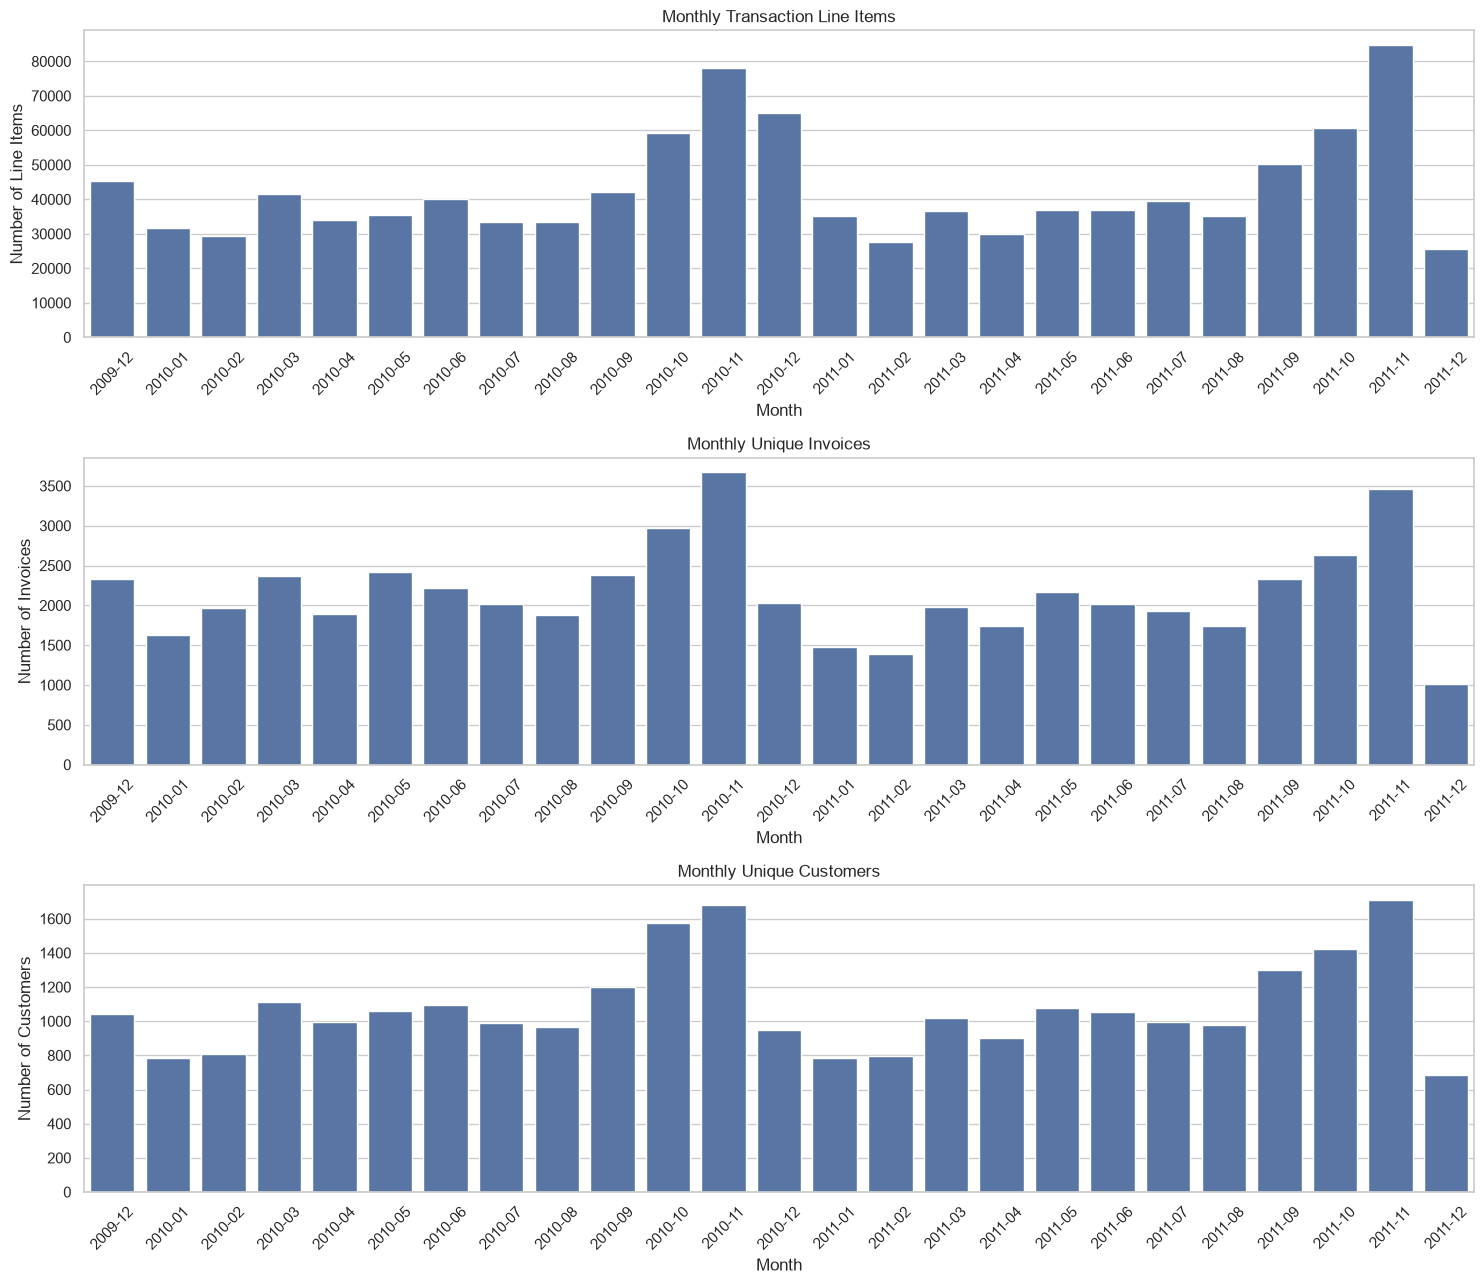

In [24]:

import matplotlib.pyplot as plt
import seaborn as sns

# Extract year-month from transaction dates
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

# Count transaction line items per month
monthly_records = df.groupby("YearMonth").size()

print("Monthly transaction line items:")
display(monthly_records)

# Count unique invoices per month
monthly_invoices = df.groupby("YearMonth")["Invoice"].nunique()

print("\nMonthly unique invoices:")
display(monthly_invoices)

# Count unique identifiable customers per month
monthly_customers = df.groupby("YearMonth")["Customer ID"].nunique()

print("\nMonthly unique customers:")
display(monthly_customers)


# -----------------------------------------
# VISUALIZATION
# -----------------------------------------

# Combine monthly metrics for visualization
monthly_coverage = pd.DataFrame({
    "records": monthly_records,
    "invoices": monthly_invoices,
    "customers": monthly_customers
})

# Convert PeriodIndex to string for plotting
monthly_coverage.index = monthly_coverage.index.astype(str)

# Set visualization style
sns.set_theme(style="whitegrid")

# Create three vertically stacked bar charts
fig, axes = plt.subplots(3, 1, figsize=(15, 13))

# 1. Monthly transaction line items
sns.barplot(
    x=monthly_coverage.index,
    y=monthly_coverage["records"],
    ax=axes[0]
)
axes[0].set_title("Monthly Transaction Line Items")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of Line Items")

# 2. Monthly unique invoices
sns.barplot(
    x=monthly_coverage.index,
    y=monthly_coverage["invoices"],
    ax=axes[1]
)
axes[1].set_title("Monthly Unique Invoices")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of Invoices")

# 3. Monthly unique customers
sns.barplot(
    x=monthly_coverage.index,
    y=monthly_coverage["customers"],
    ax=axes[2]
)
axes[2].set_title("Monthly Unique Customers")
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Number of Customers")

# Improve readability
for ax in axes:
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [25]:
# Keep records with identifiable customer IDs
identified_customers = df.dropna(subset=["Customer ID"])

# Calculate recorded activity coverage for each customer
customer_coverage = (
    identified_customers
    .groupby("Customer ID")
    .agg(
        first_recorded_date=("InvoiceDate", "min"),
        last_recorded_date=("InvoiceDate", "max"),
        line_items=("Invoice", "size"),
        unique_invoices=("Invoice", "nunique")
    )
)

print("Customer coverage statistics:")
display(customer_coverage.describe())

print("\nCustomers with the earliest first recorded activity:")
display(customer_coverage.nsmallest(10, "first_recorded_date"))

print("\nCustomers with the latest last recorded activity:")
display(customer_coverage.nlargest(10, "last_recorded_date"))

Customer coverage statistics:


,first_recorded_date,last_recorded_date,line_items,unique_invoices
count,5942,5942,5942.000000,5942.000000
mean,2010-08-18 07:44:19.851901,2011-05-21 02:16:04.069337,138.735106,7.552339
min,2009-12-01 07:45:00,2009-12-01 09:55:00,1.000000,1.000000
25%,2010-02-03 15:28:30,2010-11-23 14:38:00,21.000000,2.000000
50%,2010-06-21 10:21:30,2011-09-05 00:30:00,53.000000,4.000000
75%,2011-01-23 02:23:30,2011-11-15 11:08:15,144.000000,8.000000
max,2011-12-09 12:16:00,2011-12-09 12:50:00,13097.000000,510.000000
std,NaN,NaN,359.689585,15.972262



Customers with the earliest first recorded activity:


,first_recorded_date,last_recorded_date,line_items,unique_invoices
Customer ID,,,,
13085.0,2009-12-01 07:45:00,2011-07-05 12:11:00,92,10
13078.0,2009-12-01 09:06:00,2011-12-08 18:48:00,855,95
15362.0,2009-12-01 09:08:00,2010-09-17 10:37:00,40,2
18102.0,2009-12-01 09:24:00,2011-12-09 11:50:00,1068,153
12682.0,2009-12-01 09:28:00,2011-12-06 10:00:00,1042,53
18087.0,2009-12-01 09:43:00,2011-09-02 15:12:00,95,21
13635.0,2009-12-01 09:46:00,2011-10-03 10:55:00,167,6
14110.0,2009-12-01 09:50:00,2011-12-06 12:26:00,403,35
12636.0,2009-12-01 09:55:00,2009-12-01 09:55:00,1,1



Customers with the latest last recorded activity:


,first_recorded_date,last_recorded_date,line_items,unique_invoices
Customer ID,,,,
12680.0,2011-08-18 15:44:00,2011-12-09 12:50:00,53,4
13113.0,2010-03-28 16:13:00,2011-12-09 12:49:00,498,60
15804.0,2011-05-25 10:12:00,2011-12-09 12:31:00,274,19
13777.0,2009-12-02 09:47:00,2011-12-09 12:25:00,434,73
17581.0,2009-12-03 12:34:00,2011-12-09 12:21:00,881,53
12748.0,2009-12-04 17:31:00,2011-12-09 12:20:00,7307,365
12713.0,2011-12-09 12:16:00,2011-12-09 12:16:00,38,1
12526.0,2011-09-06 14:19:00,2011-12-09 12:09:00,71,3
16705.0,2009-12-09 13:34:00,2011-12-09 12:08:00,722,61


In [27]:
# Define a preliminary prediction snapshot
candidate_snapshot = pd.Timestamp("2011-09-10")

# Count customers whose first recorded activity was on or before the snapshot
customers_observed_by_snapshot = (
    customer_coverage["first_recorded_date"] <= candidate_snapshot
).sum()

# Count customers whose first recorded activity was after the snapshot
customers_first_seen_after_snapshot = (
    customer_coverage["first_recorded_date"] > candidate_snapshot
).sum()

# Count customers whose last recorded activity was on or before the snapshot
customers_last_seen_by_snapshot = (
    customer_coverage["last_recorded_date"] <= candidate_snapshot
).sum()

# Count customers with recorded activity after the snapshot
customers_seen_after_snapshot = (
    customer_coverage["last_recorded_date"] > candidate_snapshot
).sum()

print("Candidate snapshot:", candidate_snapshot.date())
print("Customers first observed by snapshot:", customers_observed_by_snapshot)
print("Customers first observed after snapshot:", customers_first_seen_after_snapshot)
print("Customers whose last recorded activity was by snapshot:", customers_last_seen_by_snapshot)
print("Customers with recorded activity after snapshot:", customers_seen_after_snapshot)

Candidate snapshot: 2011-09-10
Customers first observed by snapshot: 5346
Customers first observed after snapshot: 596
Customers whose last recorded activity was by snapshot: 3024
Customers with recorded activity after snapshot: 2918


In [28]:
# Define the conservative candidate snapshot
candidate_snapshot = pd.Timestamp("2011-09-09 23:59:59")

# Define the end of the 90-day observation window
observation_window_end = candidate_snapshot + pd.Timedelta(days=90)

# Compare with the final timestamp in the dataset
dataset_end = df["InvoiceDate"].max()

print("Candidate snapshot:", candidate_snapshot)
print("90-day observation window ends:", observation_window_end)
print("Dataset ends:", dataset_end)

print("\nIs the complete 90-day window covered?",
      dataset_end >= observation_window_end)

Candidate snapshot: 2011-09-09 23:59:59
90-day observation window ends: 2011-12-08 23:59:59
Dataset ends: 2011-12-09 12:50:00

Is the complete 90-day window covered? True


# Dataset Feasibility Assessment

**Project:** Customer Intelligence & Revenue Optimization  
**Phase:** Phase 2 — Dataset Acquisition & Feasibility Assessment  
**Status:** Completed  
**Assessment date:** November 26, 2026  
**Dataset:** UCI Online Retail II

---

## 1. Executive Summary

The UCI Online Retail II dataset has been selected for this project and successfully loaded into Jupyter Notebook using Pandas.

The dataset contains 1,067,371 transaction line items across two worksheets, covering December 1, 2009, to December 9, 2011. It provides sufficient transaction history and customer identifiers for customer behavior analysis, revenue analysis, segmentation, and the development of a purchase-inactivity prediction model.

The initial investigation identified several data-quality considerations, including missing customer identifiers, cancellation invoices, negative quantities, zero or negative prices, unusually large transactions, and non-merchandise financial entries.

The dataset is considered feasible for the project, subject to further data-quality assessment, transaction classification, cleaning, and target-definition work.

## 2. Dataset Information

| Attribute | Details |
|---|---|
| Dataset name | Online Retail II |
| Source | UCI Machine Learning Repository |
| Dataset URL | https://archive.ics.uci.edu/dataset/502/online+retail+ii |
| DOI | https://doi.org/10.24432/C5CG6D |
| Original publication year | 2012 |
| License | CC BY 4.0 |
| Business context | UK-based non-store online retailer |
| Dataset format | Excel workbook |
| Local filename | `online_retail_II.xlsx` |
| File size | Approximately 43.51 MB |
| Observation period | December 1, 2009 – December 9, 2011 |
| Total records | 1,067,371 transaction line items |

**Dataset citation:**

Chen, D. (2012). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D.

Attribution must be retained in project documentation in accordance with the dataset license.

## 3. Dataset Structure and Initial Inspection

The workbook contains two worksheets:

- `Year 2009-2010`
- `Year 2010-2011`

Both worksheets contain the same eight columns:

| Column | Initial data type | Description |
|---|---|---|
| Invoice | Object | Invoice identifier |
| StockCode | Object | Product or stock identifier |
| Description | Object | Product description |
| Quantity | Integer | Quantity recorded on the transaction line |
| InvoiceDate | Datetime | Transaction date and time |
| Price | Float | Price recorded for the transaction line |
| Customer ID | Float | Customer identifier |
| Country | String | Customer country |

The worksheets were successfully loaded and concatenated into a single Pandas DataFrame.

```python
df_2009_2010 = pd.read_excel(
    DATA_PATH,
    sheet_name="Year 2009-2010"
)

df_2010_2011 = pd.read_excel(
    DATA_PATH,
    sheet_name="Year 2010-2011"
)

df = pd.concat(
    [df_2009_2010, df_2010_2011],
    ignore_index=True
)
```

**Combined dataset dimensions:** 1,067,371 rows × 8 columns.

Each row represents a transaction line item, not necessarily an individual invoice or complete order. A single invoice can contain multiple product lines.

## 4. Initial Dataset Profile

### 4.1 General statistics

| Metric | Result |
|---|---:|
| Transaction line items | 1,067,371 |
| Unique invoice identifiers | 53,628 |
| Identifiable customers | 5,942 |
| Earliest transaction | 2009-12-01 07:45:00 |
| Latest transaction | 2011-12-09 12:50:00 |
| Unique observation months | 25 |

The average invoice contains approximately 19.90 transaction line items, while the median is 9. The maximum observed number of line items associated with one invoice identifier is 1,350.

### 4.2 Missing values

| Column | Missing records | Percentage |
|---|---:|---:|
| Description | 4,382 | 0.41% |
| Customer ID | 243,007 | 22.77% |
| Other columns | 0 | 0% |

Missing customer identifiers prevent reliable attribution of those records to individual customers.

**Preliminary handling decision:** Do not automatically delete records with missing Customer IDs. They may still contribute to overall transaction, product, and revenue analysis where appropriate. However, they cannot be used for customer-level analysis without a valid customer identifier.

Missing descriptions also require investigation before deciding whether records should be excluded or retained.

## 5. Transaction and Data Quality Findings

The following findings are based on initial inspection. They are not yet final cleaning rules.

### 5.1 Cancellation invoices and negative quantities

An initial check identified:

| Metric | Records |
|---|---:|
| Invoice identifiers beginning with `C` | 19,494 line items |
| Unique cancellation invoice identifiers | 8,292 |
| Negative-quantity line items | 22,950 |
| Unique invoices containing negative quantities | 11,684 |
| Negative quantities under non-cancellation invoice identifiers | 3,457 |
| Non-negative quantities under cancellation invoice identifiers | 1 |

These results show that cancellation invoice identifiers and negative quantities are related but not interchangeable classifications.

**Preliminary decision:** Investigate and maintain separate indicators for cancellation invoice identifiers and negative quantities. Do not assume that every negative quantity is a cancellation or that every cancellation invoice follows the same transaction pattern.

### 5.2 Quantity anomalies

| Statistic | Quantity |
|---|---:|
| Mean | 9.94 |
| Standard deviation | 172.71 |
| Minimum | -80,995 |
| Median | 3 |
| Maximum | 80,995 |

Some unusually large quantities appear in matching positive and negative transaction pairs.

Examples include:

- Customer `12346`: 74,215 units recorded on an invoice and -74,215 units on a cancellation invoice two minutes later.
- Customer `16446`: 80,995 units recorded on an invoice and -80,995 units on a cancellation invoice twelve minutes later.

Other high-quantity records include large quantities of products priced at relatively low unit prices, which may reflect wholesale purchasing behavior.

**Preliminary decision:** Do not remove extreme quantities solely because they are statistically unusual. Investigate their transaction context and retain legitimate wholesale transactions where appropriate.

### 5.3 Price anomalies

| Statistic | Price |
|---|---:|
| Mean | 4.65 |
| Standard deviation | 123.55 |
| Minimum | -53,594.36 |
| Median | 2.10 |
| Maximum | 38,970.00 |
| Zero-price records | 6,202 |
| Negative-price records | 5 |

The five negative-price records all have:

- StockCode: `B`
- Description: `Adjust bad debt`
- Missing Customer ID
- Country: United Kingdom

These are accounting adjustments rather than ordinary merchandise sales.

The initial inspection also identified high-value entries associated with descriptions such as `AMAZON FEE`, `BANK CHARGES`, and `Manual`.

Zero-price records include descriptions such as `short`, `lost`, `damages`, and other operational notes. They should not automatically be interpreted as free merchandise or invalid transactions.

**Preliminary decision:** Separate ordinary merchandise transactions from accounting and administrative entries before calculating customer revenue or constructing purchase features.

### 5.4 Negative quantities under non-cancellation invoices

A targeted investigation checked negative quantities under invoice identifiers that do not begin with `C`, with positive prices.

Result:

- Records found: 0
- Unique invoices: 0

This indicates that the 3,457 negative-quantity records under non-cancellation invoice identifiers have non-positive prices. Most may represent zero-price operational adjustments, but this interpretation requires further verification.

## 6. Monthly Data Coverage

The dataset contains 25 consecutive calendar months, from December 2009 through December 2011. No completely missing calendar month was identified.

November has the highest recorded activity in both years:

| Month | Transaction line items | Unique invoices | Identifiable customers |
|---|---:|---:|---:|
| November 2010 | 78,015 | 3,669 | 1,683 |
| November 2011 | 84,711 | 3,462 | 1,711 |

This may indicate seasonal activity, but further analysis is required before drawing conclusions about seasonality or its causes.

**Important limitation:** December 2011 is incomplete because the dataset ends on December 9. Its monthly totals should not be compared directly with full calendar months.

Monthly counts from this initial investigation include all recorded line items, including cancellations and operational or non-merchandise entries. They are not yet counts of qualifying purchases.

## 7. Customer Observation Coverage

The dataset contains 5,942 customers with identifiable Customer IDs.

| Metric | Result |
|---|---:|
| Mean recorded line items per customer | 138.74 |
| Median recorded line items per customer | 53 |
| Maximum recorded line items per customer | 13,097 |
| Mean unique invoices per customer | 7.55 |
| Median unique invoices per customer | 4 |
| Maximum unique invoices per customer | 510 |

Customer activity is highly uneven. The mean number of line items is considerably higher than the median, suggesting that a relatively small number of customers have substantially larger recorded transaction histories.

Customers also have different first and last recorded activity dates. These dates represent the customer's presence in the available dataset, not necessarily their actual acquisition date or confirmed churn date.

## 8. Preliminary Prediction Window Feasibility

The project intends to investigate whether historical customer behavior can predict future purchase inactivity.

A preliminary target concept is:

> A customer is classified as purchase-inactive if they make no qualifying purchase during the 90-day period following a defined prediction snapshot.

This is a behavioral inactivity definition, not proof of permanent customer churn.

### 8.1 Candidate snapshot

The dataset's final transaction timestamp is December 9, 2011, at 12:50:00.

To ensure a complete 90-calendar-day future observation window, September 9, 2011, was selected as a conservative candidate snapshot.

| Component | Date |
|---|---|
| Prediction snapshot | September 9, 2011, 23:59:59 |
| Observation window starts | September 10, 2011 |
| Observation window ends | December 8, 2011, 23:59:59 |
| Dataset end | December 9, 2011, 12:50:00 |
| Complete observation window | Yes |

The 90-day observation window is fully covered by the dataset.

### 8.2 Customer coverage at the September 10 boundary

Using September 10, 2011, as the preliminary boundary for the initial customer coverage check:

| Measure | Customers |
|---|---:|
| Total identifiable customers | 5,942 |
| First observed by the boundary | 5,346 |
| First observed after the boundary | 596 |
| Last recorded activity by the boundary | 3,024 |
| Recorded activity after the boundary | 2,918 |

Of the 5,346 customers already observed by the boundary, 2,322 also have recorded activity afterward.

These are raw recorded-activity counts. They must not be interpreted as confirmed active or inactive customer labels because the transaction records have not yet been classified into qualifying purchases.

Customers first observed after the prediction snapshot cannot be included in a model as if their customer histories were available at that snapshot.

### 8.3 Target-definition limitations

The following decisions remain open:

1. Define which transaction records qualify as actual purchases.
2. Define customer eligibility based on available historical purchase information.
3. Finalize the inactivity-label construction and observation-window convention.
4. Prevent data leakage by ensuring all model features use information available at or before the prediction snapshot.
5. Consider whether a 180-day inactivity definition should be examined as a sensitivity analysis, subject to data coverage and methodology.

## 9. Known Dataset Limitations

The dataset does not contain:

- Subscription status or explicit customer cancellation labels.
- Marketing campaign exposure or campaign costs.
- Product acquisition costs or profit margins.
- Customer acquisition costs.
- Customer demographic attributes.

Consequently:

- The project must not claim to predict subscription cancellations.
- The predictive target must be framed as future purchase inactivity.
- Revenue must not be described as profit.
- Customer lifetime value estimates must disclose their assumptions.
- Retention ROI cannot be calculated reliably without cost and margin information.
- Revenue-at-risk estimates must be clearly qualified as historical revenue associated with customers meeting a defined risk criterion, not guaranteed future losses.